<a href="https://colab.research.google.com/github/diogenesjusto/FIAP/blob/master/MBAIA/18DTSR/18DTSR_Aula3_Tecnicas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 0. Carga de bibliotecas
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

In [2]:
# 1. Carga de dados
df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv")

/tmp/ipykernel_1741/438629623.py:2: DtypeWarning: Columns (52,53) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("https://raw.githubusercontent.com/diogenesjusto/FIAP/refs/heads/master/dados/credit_features_formatado.csv")


array([[<Axes: title={'center': 'RENDA_PESSOAL_MENSAL'}>]], dtype=object)

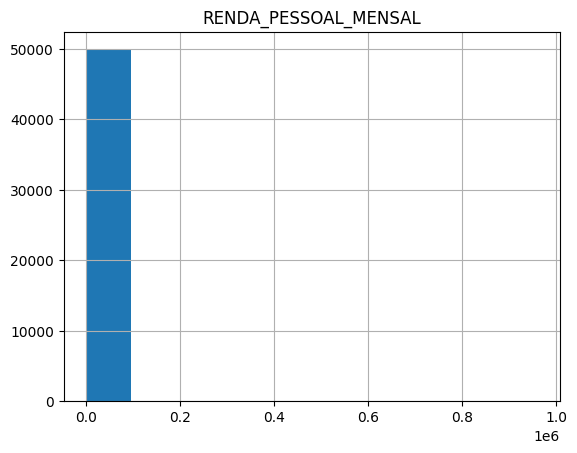

In [3]:
# Análise de distribuição da variável Renda
df.hist('RENDA_PESSOAL_MENSAL')

## DISCRETIZAÇÃO: Transformar dados ou variáveis numéricas em categóricas
Por exemplo: renda por percentis, por classe social, por salários mínimos, por tributação, etc

1. Discretização por largura fixa



In [4]:
!pip install feature_engine

In [12]:
from feature_engine.discretisation import EqualWidthDiscretiser

discEW = EqualWidthDiscretiser(bins=10, variables='RENDA_PESSOAL_MENSAL')
discEW.fit(df)
df_transf = discEW.transform(df)
df_transf.groupby('RENDA_PESSOAL_MENSAL').count()

,Unnamed: 0,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,...,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU=1
RENDA_PESSOAL_MENSAL,,,,,,,,,,,,,,,,,,,,,
0,49974,49974,49974,49974,49974,49974,49974,49974,49974,49974,...,49974,49974,49974,49974,49974,49974,49974,49974,49974,49974
1,18,18,18,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
2,3,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
3,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
5,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
9,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2


2. Discretização por mesma quantidade de elementos

In [17]:
from sklearn.preprocessing import KBinsDiscretizer

discKB = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile')
discKB.fit(df[['RENDA_PESSOAL_MENSAL']])
df_transf2 = discKB.transform(df[['RENDA_PESSOAL_MENSAL']])

df['RENDA_PESSOAL_MENSAL_Discretized'] = df_transf2
df.groupby('RENDA_PESSOAL_MENSAL_Discretized').count()

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


,Unnamed: 0,ID_CLIENTE,TIPO_FUNCIONARIO,DIA_PAGAMENTO,TIPO_ENVIO_APLICACAO,QUANT_CARTOES_ADICIONAIS,TIPO_ENDERECO_POSTAL,SEXO,ESTADO_CIVIL,QUANT_DEPENDENTES,...,FLAG_DOCUMENTO_RESIDENCIAL,FLAG_RG,FLAG_CPF,FLAG_COMPROVANTE_RENDA,PRODUTO,FLAG_REGISTRO_ACSP,IDADE,CEP_RESIDENCIAL_3,CEP_PROFISSIONAL_3,ROTULO_ALVO_MAU=1
RENDA_PESSOAL_MENSAL_Discretized,,,,,,,,,,,,,,,,,,,,,
0.0,4552,4552,4552,4552,4552,4552,4552,4552,4552,4552,...,4552,4552,4552,4552,4552,4552,4552,4552,4552,4552
1.0,9319,9319,9319,9319,9319,9319,9319,9319,9319,9319,...,9319,9319,9319,9319,9319,9319,9319,9319,9319,9319
2.0,6080,6080,6080,6080,6080,6080,6080,6080,6080,6080,...,6080,6080,6080,6080,6080,6080,6080,6080,6080,6080
3.0,4462,4462,4462,4462,4462,4462,4462,4462,4462,4462,...,4462,4462,4462,4462,4462,4462,4462,4462,4462,4462
4.0,5575,5575,5575,5575,5575,5575,5575,5575,5575,5575,...,5575,5575,5575,5575,5575,5575,5575,5575,5575,5575
5.0,4181,4181,4181,4181,4181,4181,4181,4181,4181,4181,...,4181,4181,4181,4181,4181,4181,4181,4181,4181,4181
6.0,5830,5830,5830,5830,5830,5830,5830,5830,5830,5830,...,5830,5830,5830,5830,5830,5830,5830,5830,5830,5830
7.0,5001,5001,5001,5001,5001,5001,5001,5001,5001,5001,...,5001,5001,5001,5001,5001,5001,5001,5001,5001,5001
8.0,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,...,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
